# 17 · Landkarten mit geopandas

**Ausblick:** Dieses Notebook ist eine Vorführung ohne Übungen.

**Lernziele**

- Du weißt, was Geodaten sind: eine Tabelle mit einer Spalte für die Form.
- Du kennst die Grundformen Punkt, Linie und Fläche und weißt, warum es verschiedene Koordinatensysteme gibt.
- Du färbst die Landkreise Deutschlands nach einer Kennzahl ein.
- Du filterst eine Karte auf ein Bundesland und erstellst eine interaktive Karte, die beim Darüberfahren Werte zeigt.
- Du ordnest Orte automatisch dem Kreis zu, in dem sie liegen.

## Was ist geopandas?

In Notebook 15 hast du mit pandas Tabellen ausgewertet. **geopandas** erweitert pandas um eine Spalte, die eine Form enthält: den Umriss eines Landkreises, den Verlauf einer Straße, die Lage einer Filiale. Alles, was du aus pandas kennst, funktioniert weiter. Dazu kommt:

- Geodateien lesen und schreiben (GeoJSON, Shapefile, GeoPackage),
- Karten zeichnen, statisch oder interaktiv,
- mit Formen rechnen: Fläche, Entfernung, liegt ein Punkt in einer Fläche?
- Tabellen über die Lage verbinden statt über eine gemeinsame Spalte.

| Klasse | steht für | kennst du aus pandas als |
| --- | --- | --- |
| `GeoDataFrame` | Tabelle mit einer Spalte `geometry` | `DataFrame` |
| `GeoSeries` | die Spalte `geometry` selbst | `Series` |
| `Point`, `LineString`, `Polygon` | eine einzelne Form (Paket shapely) | ein einzelner Wert |

![Ein GeoDataFrame mit drei Zeilen: Schlüssel, Kreisname und eine orange markierte Spalte geometry mit Einträgen wie POLYGON ((468542 5521287, …)). Ein Pfeil .plot() führt zu drei gezeichneten Umrissen: Lahn-Dill-Kreis, Frankfurt, Darmstadt. Darunter: Jede Zeile ist ein Kreis, geometry enthält seinen Umriss als Liste von Koordinaten in Metern.](../assets/17_geodataframe.png)

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
from shapely.geometry import LineString, Point, Polygon

## Die Grundformen

Jede Form ist aus Koordinaten gebaut, also aus Paaren von Zahlen. Ein Punkt ist ein Paar, eine Linie eine Folge von Punkten, eine Fläche ein geschlossener Umriss. Welche Zahlen das sind, legt das **Koordinatensystem** fest (englisch *coordinate reference system*, kurz CRS):

![Drei Kästen: Punkt (ein Paar Koordinaten, z. B. eine Filiale) mit Point(8.68, 50.11), Linie (Punkte der Reihe nach verbunden, z. B. eine Straße) mit LineString, Fläche (geschlossener Umriss, z. B. ein Kreis) mit Polygon. Darunter zwei Koordinatensysteme: EPSG:4326 mit Länge und Breite in Grad, weltweit, wie bei Navi und Webkarten; EPSG:25832 mit x und y in Metern, von den Vermessungsämtern in Deutschland, rechnet in m und km².](../assets/17_geometrien.png)

Bevor wir echte Karten laden, bauen wir ein kleines Werksgelände von Hand, in Metern: das Gelände als Fläche, ein Förderband als Linie, die Pforte als Punkt. Die Formen kommen in die Spalte `geometry`, die übrigen Spalten sind ganz normale pandas-Spalten:

In [2]:
werk = gpd.GeoDataFrame(
    {"Name": ["Werksgelände", "Förderband", "Pforte"]},
    geometry=[
        Polygon([(0, 0), (60, 0), (60, 40), (0, 40)]),
        LineString([(10, 10), (30, 20), (50, 20)]),
        Point(45, 35),
    ],
)
werk

,Name,geometry
0,Werksgelände,"POLYGON ((0 0, 60 0, 60 40, 0 40, 0 0))"
1,Förderband,"LINESTRING (10 10, 30 20, 50 20)"
2,Pforte,POINT (45 35)


Jetzt rechnet geopandas mit den Formen, wie pandas mit Zahlen: für die ganze Spalte auf einmal. `area` ist die Fläche (hier m²), `length` die Länge einer Linie oder der Umfang einer Fläche. `contains()` prüft, ob eine Form eine andere enthält:

['Polygon', 'LineString', 'Point']
[2400.0, 0.0, 0.0]
[200.0, 42.4, 0.0]
True
False


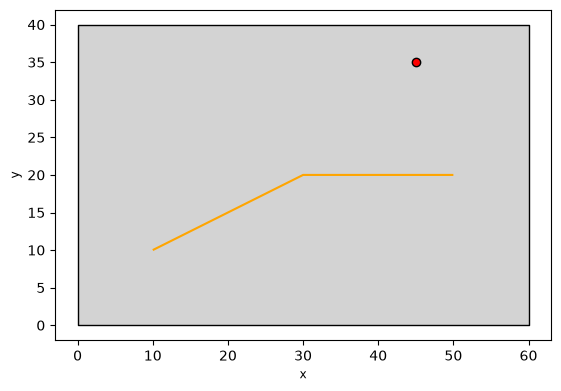

In [3]:
print(werk.geom_type.tolist())
print(werk.area.tolist())
print(werk.length.round(1).tolist())

gelaende = werk.geometry[0]
pforte = werk.geometry[2]
print(gelaende.contains(pforte))
print(gelaende.contains(Point(70, 10)))

werk.plot(color=["lightgrey", "orange", "red"], edgecolor="black");

## Die Kreise Deutschlands

Die Datei `daten/kreise.gpkg` enthält die Umrisse aller 400 Kreise und kreisfreien Städte. Sie ist ein **GeoPackage**, ein verbreitetes Format für Geodaten: eine einzige Datei, die Tabelle, Formen und Koordinatensystem zusammen speichert.

**Woher die Daten kommen:** Das Bundesamt für Kartographie und Geodäsie (BKG) veröffentlicht die Verwaltungsgrenzen Deutschlands als freie Daten, in mehreren Genauigkeiten. Wir nutzen das gröbste Produkt, *Verwaltungsgebiete 1:2 500 000* (VG2500), Stand 31.12.2024. Für diesen Maßstab hat das BKG die Grenzen vereinfacht: Sie reichen für eine Deutschlandkarte, die Datei bleibt klein. Geliefert wird eine ZIP-Datei mit Shapefiles:

```
https://daten.gdz.bkg.bund.de/produkte/vg/vg2500/2024/vg2500_12-31.utm32s.shape.zip
```

Das Skript `tools/make_karten_data.py` hat daraus die Kreise als GeoPackage gespeichert und nur die Spalten Schlüssel, Name und Art behalten und umbenannt. Die Umrisse und ihre Koordinaten sind unverändert.

Die Daten stehen unter der *Datenlizenz Deutschland – Namensnennung – 2.0* (https://www.govdata.de/dl-de/by-2-0). Sie verlangt einen Quellenvermerk und, wenn die Daten bearbeitet wurden, einen Hinweis darauf. Den Wortlaut gibt das BKG in den Nutzungsbedingungen im ZIP vor; die Liste dort verlinkt die Behörden, deren Daten in VG2500 stecken.

*Quellenvermerk: © BKG (2026) dl-de/by-2-0 (Daten verändert), Datenquellen: https://sgx.geodatenzentrum.de/web_public/gdz/datenquellen/datenquellen_vg_nuts.pdf*

`gpd.read_file()` liest die Datei, wie `pd.read_csv()` eine CSV-Datei:

In [4]:
kreise = gpd.read_file("../daten/kreise.gpkg")
print(type(kreise), len(kreise))
kreise.head()

<class 'geopandas.geodataframe.GeoDataFrame'> 400


,Schluessel,Kreis,Art,geometry
0,01001,Flensburg,Kreisfreie Stadt,"POLYGON ((531470.957 6075201.09, 532435.433 60..."
1,01002,Kiel,Kreisfreie Stadt,"POLYGON ((577310.28 6027466.911, 576863.752 60..."
2,01003,Lübeck,Kreisfreie Stadt,"POLYGON ((624204.438 5980391.723, 624886.676 5..."
3,01004,Neumünster,Kreisfreie Stadt,"POLYGON ((567602.493 5998385.945, 566865.243 5..."
4,01051,Dithmarschen,Kreis,"MULTIPOLYGON (((479551.742 5990180.683, 479871..."


Die Spalte `Art` unterscheidet die Kreistypen. „Kreis“ und „Landkreis“ meinen dasselbe, „Stadtkreis“ ist in Baden-Württemberg der Name für eine kreisfreie Stadt:

In [ ]:
kreise["Art"].value_counts()

Der Schlüssel ist der amtliche Regionalschlüssel: Die ersten zwei Ziffern sind das Bundesland, `06` steht für Hessen. Die Koordinaten sind große Zahlen, weil sie in Metern zählen. Was sie bedeuten, verrät das Koordinatensystem `crs`: EPSG:25832, ein System der deutschen Vermessungsämter (UTM-Zone 32). Die Datei bringt diese Angabe mit, geopandas liest sie automatisch:

In [7]:
kreise.crs

<Projected CRS: EPSG:25832>
Name: ETRS89 / UTM zone 32N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Europe between 6°E and 12°E: Austria; Denmark - onshore and offshore; Germany - onshore and offshore; Italy - onshore and offshore; Norway including Svalbard - onshore and offshore; Spain - offshore.
- bounds: (6.0, 36.53, 12.01, 84.01)
Coordinate Operation:
- name: UTM zone 32N
- method: Transverse Mercator
Datum: European Terrestrial Reference System 1989 ensemble
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

`plot()` zeichnet die Umrisse. `set_axis_off()` blendet die Achsen aus, die Meterzahlen braucht auf einer Karte niemand:

In [ ]:
ax = kreise.plot(figsize=(12, 14), color="white", edgecolor="grey", linewidth=0.5)
ax.set_axis_off()

Weil die Koordinaten Meter sind, liefert `area` Quadratmeter. Geteilt durch eine Million ergibt das km², als neue Spalte wie in pandas:

In [9]:
kreise["Flaeche_km2"] = (kreise.area / 1_000_000).round(1)
kreise[["Kreis", "Art", "Flaeche_km2"]].head()

,Kreis,Art,Flaeche_km2
0,Flensburg,Kreisfreie Stadt,53.1
1,Kiel,Kreisfreie Stadt,121.6
2,Lübeck,Kreisfreie Stadt,221.0
3,Neumünster,Kreisfreie Stadt,80.8
4,Dithmarschen,Kreis,1448.0


## Einwohner dazuholen

Die Umrisse allein zeigen noch nichts. Die Einwohnerzahl je Kreis steht in einer zweiten Datei, einer CSV-Datei im deutschen Format wie in Notebook 15. Sie nennt auch das Bundesland jedes Kreises.

Achtung beim Schlüssel: pandas würde `06411` als Zahl lesen und die führende Null verlieren. `dtype={"Schluessel": str}` liest die Spalte als Text.

**Woher die Daten kommen:** Statistisches Bundesamt, Gemeindeverzeichnis, Tabelle *Kreisfreie Städte und Landkreise nach Fläche, Bevölkerung und Bevölkerungsdichte*, Stand 31.12.2024:

```
https://www.destatis.de/DE/Themen/Laender-Regionen/Regionales/Gemeindeverzeichnis/Administrativ/04-kreise.xlsx?__blob=publicationFile
```

`tools/make_karten_data.py` hat daraus fünf Spalten übernommen (Schlüssel, Name, Bundesland, Fläche, Einwohner) und als CSV gespeichert. Die Tabelle erlaubt Vervielfältigung und Verbreitung mit Quellenangabe.

*Quellenvermerk: © Statistisches Bundesamt (Destatis), 2025*

In [10]:
einwohner = pd.read_csv(
    "../daten/kreise_bevoelkerung.csv", sep=";", decimal=",", dtype={"Schluessel": str}
)
einwohner.head()

,Schluessel,Kreis,Bundesland,Flaeche_km2,Einwohner
0,01001,"Flensburg, Stadt",Schleswig-Holstein,56.73,96326
1,01002,"Kiel, Landeshauptstadt",Schleswig-Holstein,118.65,252668
2,01003,"Lübeck, Hansestadt",Schleswig-Holstein,214.19,216889
3,01004,"Neumünster, Stadt",Schleswig-Holstein,71.66,79809
4,01051,Dithmarschen,Schleswig-Holstein,1428.17,133460


Die Namen passen nicht zusammen: `Flensburg` in der Karte, `Flensburg, Stadt` in der Statistik. Der Schlüssel ist dagegen in beiden Dateien gleich. Deshalb verbinden wir über den Schlüssel, mit `merge()` wie in Notebook 15. Für spätere Fälle zeigt die Grafik schon den zweiten Weg, den räumlichen Join; er folgt am Ende des Notebooks.

![Links merge(): eine Tabelle mit Schlüssel und geometry plus eine Tabelle mit Schlüssel und Einwohner ergibt eine Tabelle mit allen drei Spalten; gleicher Schlüssel, gleiche Zeile. Rechts sjoin(): die Punkte Wetzlar und Gießen liegen in den Flächen Lahn-Dill-Kreis und Gießen; daraus entsteht eine Tabelle Filiale und Kreis, ohne gemeinsame Spalte.](../assets/17_verbinden.png)

Beide Tabellen haben eine Spalte `Flaeche_km2`. `suffixes` hängt an die zweite `_amtlich` an, damit wir unsere berechnete Fläche mit der amtlichen vergleichen können:

In [11]:
karte = kreise.merge(
    einwohner[["Schluessel", "Bundesland", "Flaeche_km2", "Einwohner"]],
    on="Schluessel",
    suffixes=("", "_amtlich"),
)
karte["Dichte"] = (karte["Einwohner"] / karte["Flaeche_km2_amtlich"]).round()

print(type(karte), len(karte))
karte[["Kreis", "Bundesland", "Flaeche_km2", "Flaeche_km2_amtlich", "Einwohner", "Dichte"]].head()

<class 'geopandas.geodataframe.GeoDataFrame'> 400


,Kreis,Bundesland,Flaeche_km2,Flaeche_km2_amtlich,Einwohner,Dichte
0,Flensburg,Schleswig-Holstein,53.1,56.73,96326,1698.0
1,Kiel,Schleswig-Holstein,121.6,118.65,252668,2130.0
2,Lübeck,Schleswig-Holstein,221.0,214.19,216889,1013.0
3,Neumünster,Schleswig-Holstein,80.8,71.66,79809,1114.0
4,Dithmarschen,Schleswig-Holstein,1448.0,1428.17,133460,93.0


Das Ergebnis ist wieder ein `GeoDataFrame`, alle 400 Kreise haben einen Partner gefunden.

Unsere berechnete Fläche weicht von der amtlichen ab, meist um weniger als ein Prozent, bei kleinen Städten wie Neumünster um mehr als zehn Prozent. Der Grund liegt im Produkt VG2500: Das BKG hat die Umrisse für den Maßstab 1:2 500 000 vereinfacht, ein Kreis hat dort im Mittel nur rund 150 Eckpunkte. Bei großen Kreisen fällt das kaum ins Gewicht, bei kleinen schon. Die amtliche Fläche dagegen stammt aus dem Liegenschaftskataster, also aus der genauen Vermessung. Für die Dichte (Einwohner je km²) nehmen wir deshalb die amtliche Fläche. Am dichtesten und am dünnsten besiedelt:

In [12]:
columns = ["Kreis", "Art", "Einwohner", "Dichte"]
print(karte.sort_values("Dichte", ascending=False)[columns].head(5))
print()
print(karte.sort_values("Dichte")[columns].head(3))

                 Kreis               Art  Einwohner  Dichte
223            München  Kreisfreie Stadt    1505005  4844.0
324             Berlin  Kreisfreie Stadt    3685265  4136.0
117  Frankfurt am Main  Kreisfreie Stadt     756021  3045.0
108              Herne  Kreisfreie Stadt     155851  3031.0
118  Offenbach am Main  Kreisfreie Stadt     132746  2958.0

                      Kreis        Art  Einwohner  Dichte
367  Altmarkkreis Salzwedel  Landkreis      79980    35.0
339                Prignitz  Landkreis      75595    35.0
36        Lüchow-Dannenberg  Landkreis      46502    38.0


## Kreise einfärben

`plot(column="Dichte")` färbt jeden Kreis nach seinem Wert ein. Wie die Farben auf die Werte verteilt werden, hängt davon ab, wie die Werte verteilt sind. `describe()` aus Notebook 15 gibt einen Überblick:

In [13]:
karte["Dichte"].describe()

count     400.000000
mean      541.247500
std       715.394478
min        35.000000
25%       116.000000
50%       205.500000
75%       685.250000
max      4844.000000
Name: Dichte, dtype: float64

Die Hälfte der Kreise hat weniger als 206 Einwohner je km², drei Viertel weniger als 690. Nur wenige Großstädte liegen weit darüber, München mit 4844. Eine gleichmäßige Farbskala von 35 bis 4844 würde fast alle Kreise im selben Hellgelb zeigen. Besser: Wir teilen die Kreise in fünf gleich große Gruppen und geben jeder Gruppe eine Farbe.

Zur Orientierung sollen die Grenzen der Bundesländer auf die Karte. Eine eigene Datei brauchen wir dafür nicht: Jeder Kreis kennt sein Land aus der Spalte `Bundesland`. `dissolve()` fasst alle Kreise eines Landes zu einer Form zusammen, wie `groupby()` in Notebook 15 Zeilen zusammenfasst. Die inneren Kreisgrenzen verschwinden dabei; `aggfunc` sagt, was mit den anderen Spalten passiert, hier: Einwohner addieren.

In [14]:
laender = karte.dissolve(by="Bundesland", aggfunc={"Einwohner": "sum"})

print(len(laender), "Länder")
laender[["Einwohner"]].sort_values("Einwohner", ascending=False)

16 Länder


,Einwohner
Bundesland,
Nordrhein-Westfalen,18034454
Bayern,13248928
Baden-Württemberg,11245898
Niedersachsen,8004489
Hessen,6280793
Rheinland-Pfalz,4129569
Sachsen,4042422
Berlin,3685265
Schleswig-Holstein,2959517


Jetzt die Karte. Die Argumente von `plot()` der Reihe nach:

- `column="Dichte"`: nach dieser Spalte einfärben; `cmap="YlOrRd"` wählt die Farben, von Gelb über Orange nach Rot.
- `scheme="quantiles", k=5`: fünf gleich große Gruppen zu je 80 Kreisen, jede Gruppe eine Farbe (das Paket mapclassify rechnet die Grenzen aus).
- `edgecolor="grey", linewidth=0.2`: dünne graue Linien zwischen den Kreisen.
- `figsize`: Größe der Grafik in Zoll, wie bei matplotlib in Notebook 15.
- `legend=True` zeigt die Legende; `legend_kwds` stellt sie ein: Überschrift, Zahlen ohne Nachkommastellen (`fmt`), Platz rechts neben der Karte (`loc` und `bbox_to_anchor`).

`plot()` gibt die Zeichenfläche `ax` zurück. `laender.boundary` sind nur die Umrisslinien der Länder, ohne Füllung; mit `ax=ax` landen sie in derselben Zeichnung, über den Kreisen.

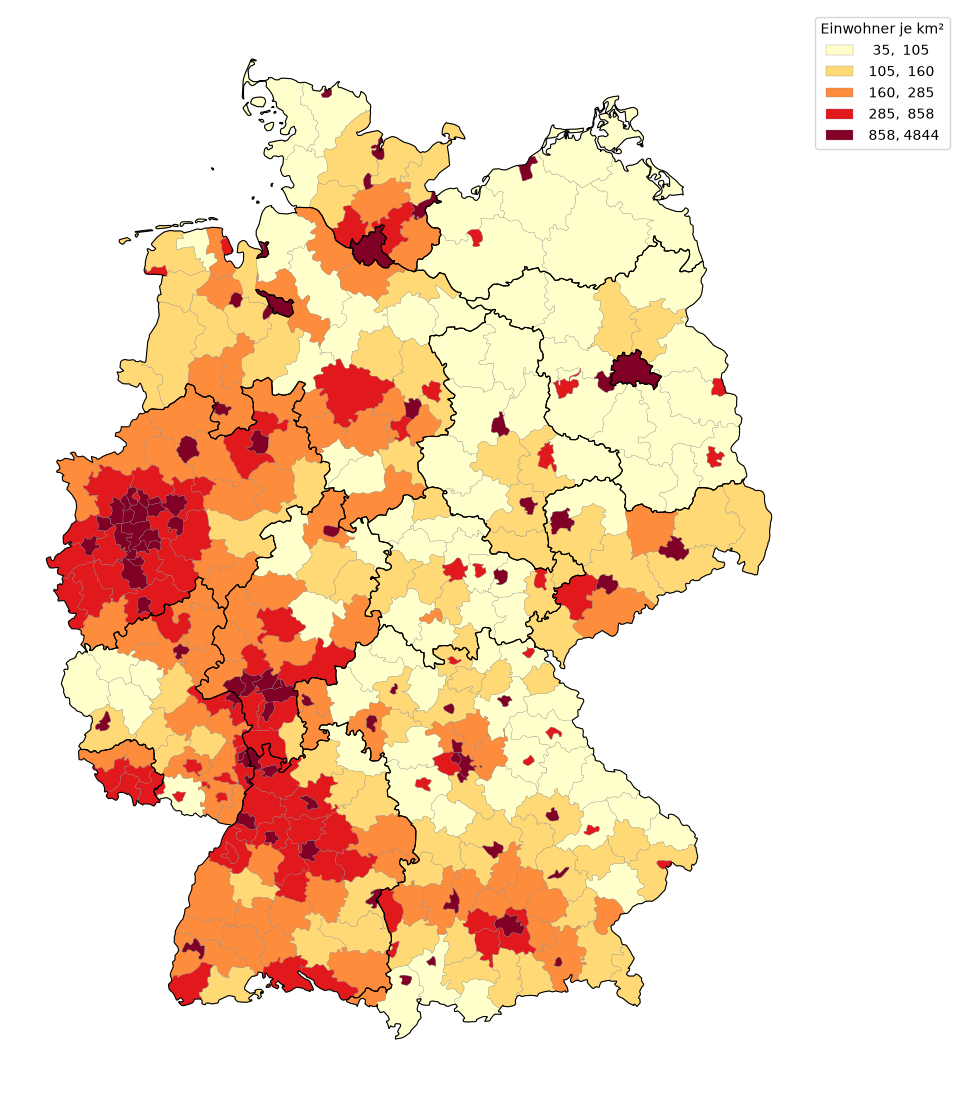

In [15]:
ax = karte.plot(
    column="Dichte",
    cmap="YlOrRd",
    scheme="quantiles",
    k=5,
    edgecolor="grey",
    linewidth=0.2,
    figsize=(12, 14),
    legend=True,
    legend_kwds={"title": "Einwohner je km²", "fmt": "{:.0f}", "loc": "upper left", "bbox_to_anchor": (1, 1)},
)
laender.boundary.plot(ax=ax, color="black", linewidth=0.8)
ax.set_axis_off()

## Nur Hessen

Ein Bundesland auszuwählen ist ein ganz normaler pandas-Filter auf die Spalte `Bundesland`. Die Namen setzen wir mit `annotate()` an einen Punkt im Inneren jedes Kreises (`representative_point()`), auf einem halb durchsichtigen weißen Kästchen (`bbox`), damit sie auch auf dunklen Flächen lesbar bleiben. Die fünf kreisfreien Städte sind zu klein für ihre Namen; sie bekommen erst in der interaktiven Karte eine Beschriftung.

26 Kreise in Hessen


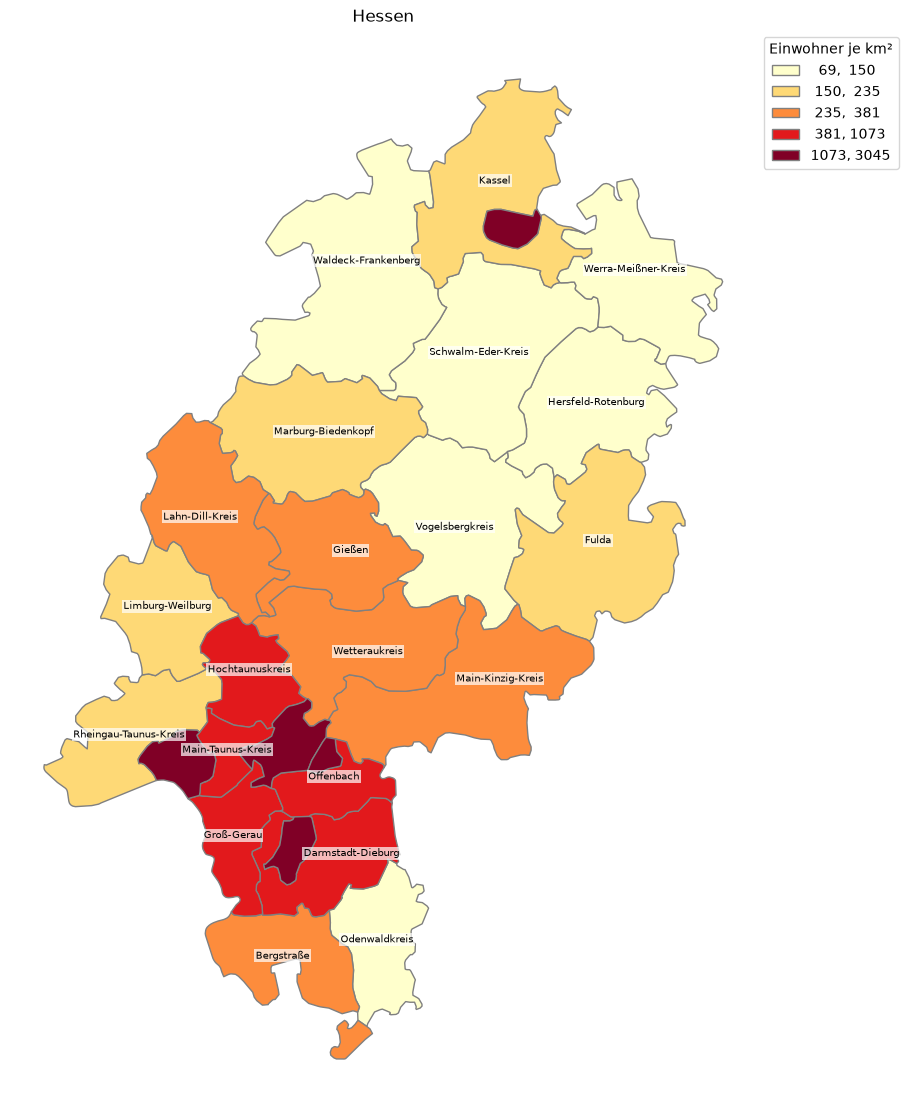

In [16]:
hessen = karte[karte["Bundesland"] == "Hessen"]
print(len(hessen), "Kreise in Hessen")

ax = hessen.plot(
    column="Dichte",
    cmap="YlOrRd",
    scheme="quantiles",
    k=5,
    edgecolor="grey",
    figsize=(12, 14),
    legend=True,
    legend_kwds={"title": "Einwohner je km²", "fmt": "{:.0f}", "loc": "upper left", "bbox_to_anchor": (1, 1)},
)
label_box = {"facecolor": "white", "alpha": 0.7, "edgecolor": "none", "pad": 1}
for _, row in hessen[hessen["Art"] == "Landkreis"].iterrows():
    point = row.geometry.representative_point()
    ax.annotate(row["Kreis"], (point.x, point.y), ha="center", fontsize=7, bbox=label_box)
ax.set_title("Hessen")
ax.set_axis_off()

## Interaktive Karte

`explore()` erstellt dieselbe Karte als Webseite: Du kannst zoomen und verschieben, und wenn du mit der Maus über einen Kreis fährst, zeigt ein Hinweisfeld (Tooltip) die Spalten aus `tooltip`. Die Koordinaten rechnet `explore()` selbst in Grad um.

Den Hintergrund lädt der Browser aus dem Internet; welcher es ist, bestimmt `tiles`. Zum Beispiel, alle ohne Anmeldung nutzbar:

- `"Esri.WorldGrayCanvas"`: hellgrau ohne Beschriftung, lenkt nicht von den Farben ab
- `"OpenStreetMap"`: Straßenkarte, die Voreinstellung von `explore()`
- `None`: kein Hintergrund, nur die Kreise

Bleibt der Hintergrund leer und grau, liefert der Server gerade keine Kartenbilder; dann hilft ein anderer Hintergrund aus der Liste.

Die vollständige Liste (über 800 Hintergründe ohne Anmeldung, viele nur für einzelne Länder) steht in der Dokumentation des Pakets xyzservices, das mit folium installiert wird: https://xyzservices.readthedocs.io

`save()` speichert die Karte als HTML-Datei, die jeder Browser öffnet, auch ohne Python:

In [ ]:
interaktiv = hessen.explore(
    column="Dichte",
    cmap="YlOrRd",
    scheme="quantiles",
    k=5,
    tiles="Esri.WorldGrayCanvas",
    tooltip=["Kreis", "Art", "Einwohner", "Dichte"],
    legend_kwds={"colorbar": False, "fmt": "{:.0f}", "caption": "Einwohner je km²"},
)

out_dir = Path("../daten/ausgabe")
out_dir.mkdir(exist_ok=True)
interaktiv.save(out_dir / "hessen_karte.html")
interaktiv

## Filialen auf der Karte

Die Filialen aus den Notebooks 15 und 16 stehen in `daten/filialen.csv` mit Länge und Breite ihrer Stadtmitte, so wie man sie aus einem Navi oder einer Webkarte abliest. `gpd.points_from_xy()` macht aus den beiden Zahlenspalten Punkte; `crs="EPSG:4326"` sagt, dass es Grad sind:

In [18]:
filialen = pd.read_csv("../daten/filialen.csv", sep=";", decimal=",")
filialen = gpd.GeoDataFrame(
    filialen,
    geometry=gpd.points_from_xy(filialen["Laenge"], filialen["Breite"]),
    crs="EPSG:4326",
)
filialen

,Filiale,Breite,Laenge,geometry
0,Köln,50.9375,6.9603,POINT (6.9603 50.9375)
1,Bonn,50.7374,7.0982,POINT (7.0982 50.7374)
2,Düsseldorf,51.2277,6.7735,POINT (6.7735 51.2277)
3,Siegen,50.8748,8.0243,POINT (8.0243 50.8748)
4,Frankfurt,50.1109,8.6821,POINT (8.6821 50.1109)
5,Wetzlar,50.5558,8.5049,POINT (8.5049 50.5558)
6,Gießen,50.5841,8.6784,POINT (8.6784 50.5841)
7,Mainz,49.9929,8.2473,POINT (8.2473 49.9929)


Jetzt haben wir zwei Quellen in zwei Koordinatensystemen: die Kreise in Metern (EPSG:25832), die Filialen in Grad (EPSG:4326). Das ist in der Praxis der Normalfall. Für geopandas sind es einfach Zahlen: Frankfurt bei (8,68 | 50,11) läge in Metern gerechnet nur wenige Meter vom Nullpunkt des Meter-Systems entfernt, und der liegt am Äquator im Golf von Guinea. Fragen wir, in welchem Kreis jede Filiale liegt (`sjoin()`, gleich genauer), findet geopandas deshalb nichts und warnt vor den unterschiedlichen Systemen.

`to_crs()` rechnet alle Koordinaten in ein anderes System um. Mit `karte.crs` nehmen wir einfach das System der Kreise:

In [19]:
print(filialen.crs.name, "|", karte.crs.name)
treffer = filialen.sjoin(karte, predicate="within")
print(len(treffer), "Filialen in einem Kreis gefunden")

filialen = filialen.to_crs(karte.crs)
filialen

WGS 84 | ETRS89 / UTM zone 32N
0 Filialen in einem Kreis gefunden


/Users/michaelaydinbas/git/github/pmayd/gfu-python-einsteiger/.venv/lib/python3.15/site-packages/geopandas/geodataframe.py:2680: UserWarning: CRS mismatch between the CRS of left geometries and the CRS of right geometries.
Use `to_crs()` to reproject one of the input geometries to match the CRS of the other.

Left CRS: EPSG:4326
Right CRS: EPSG:25832

  return geopandas.sjoin(


,Filiale,Breite,Laenge,geometry
0,Köln,50.9375,6.9603,POINT (356689.074 5644855.734)
1,Bonn,50.7374,7.0982,POINT (365804.47 5622348.105)
2,Düsseldorf,51.2277,6.7735,POINT (344541.73 5677501.948)
3,Siegen,50.8748,8.0243,POINT (431352.105 5636355.789)
4,Frankfurt,50.1109,8.6821,POINT (477269.508 5551009.575)
5,Wetzlar,50.5558,8.5049,POINT (464928.453 5600547.079)
6,Gießen,50.5841,8.6784,POINT (477232.336 5603626.259)
7,Mainz,49.9929,8.2473,POINT (446048.516 5538112.745)


Weil die Filialen jetzt auch in Metern vorliegen, liefert `distance()` Entfernungen in Metern, für alle Filialen auf einmal. Wie weit liegt jede Filiale von Frankfurt entfernt (Luftlinie)?

In [20]:
frankfurt = filialen.loc[filialen["Filiale"] == "Frankfurt", "geometry"].iloc[0]
filialen["km_bis_Frankfurt"] = (filialen.distance(frankfurt) / 1000).round()
filialen[["Filiale", "km_bis_Frankfurt"]].sort_values("km_bis_Frankfurt")

,Filiale,km_bis_Frankfurt
4,Frankfurt,0.0
7,Mainz,34.0
5,Wetzlar,51.0
6,Gießen,53.0
3,Siegen,97.0
1,Bonn,132.0
0,Köln,153.0
2,Düsseldorf,183.0


In welchem Kreis liegt welche Filiale? Eine gemeinsame Spalte gibt es nicht; die Filialen-Tabelle kennt nur Koordinaten. `sjoin()` (*spatial join*, räumlicher Join) verbindet deshalb über die Lage: Jeder Punkt bekommt die Zeile der Fläche, in der er liegt (`predicate="within"`). Jetzt, im selben Koordinatensystem, findet es alle acht:

In [21]:
zuordnung = filialen.sjoin(karte[["Kreis", "Einwohner", "geometry"]], predicate="within")
zuordnung[["Filiale", "Kreis", "Einwohner"]]

,Filiale,Kreis,Einwohner
0,Köln,Köln,1024621
1,Bonn,Bonn,323336
2,Düsseldorf,Düsseldorf,618685
3,Siegen,Siegen-Wittgenstein,274074
4,Frankfurt,Frankfurt am Main,756021
5,Wetzlar,Lahn-Dill-Kreis,254074
6,Gießen,Gießen,268418
7,Mainz,Mainz,224684


Wetzlar liegt im Lahn-Dill-Kreis, Siegen im Kreis Siegen-Wittgenstein, die übrigen Filialen in kreisfreien Städten gleichen Namens. `index_right` ist die Zeilennummer des Kreises in `karte`; damit holen wir die Kreise mit Filiale und zeichnen sie mit den Punkten in eine Karte der drei Länder mit Filialen:

In [ ]:
mit_filialen = ["Nordrhein-Westfalen", "Hessen", "Rheinland-Pfalz"]
region = karte[karte["Bundesland"].isin(mit_filialen)]
kreise_mit_filiale = karte.loc[zuordnung["index_right"]]

ax = region.plot(color="whitesmoke", edgecolor="grey", linewidth=0.3, figsize=(8, 9))
kreise_mit_filiale.plot(ax=ax, color="lightblue", edgecolor="grey")
laender.loc[mit_filialen].boundary.plot(ax=ax, color="black", linewidth=0.8)
filialen.plot(ax=ax, color="red", markersize=40, zorder=3)
for _, row in filialen.iterrows():
    ax.annotate(row["Filiale"], (row.geometry.x, row.geometry.y), xytext=(6, 4), textcoords="offset points")
ax.set_axis_off()

## Zusammenfassung

- Ein `GeoDataFrame` ist ein `DataFrame` mit einer Spalte `geometry`. Filtern, Sortieren, neue Spalten und `merge()` funktionieren wie in pandas.
- Formen sind Punkte, Linien und Flächen (`Point`, `LineString`, `Polygon`), gebaut aus Koordinaten.
- Das Koordinatensystem (`crs`) sagt, was die Zahlen bedeuten: Grad (EPSG:4326) wie bei Navi und Webkarten, Meter (EPSG:25832) wie bei den Vermessungsämtern. Daten aus verschiedenen Quellen bringt `to_crs()` in dasselbe System, bevor man sie verbindet.
- `gpd.read_file()` liest Geodateien, `points_from_xy()` macht aus zwei Zahlenspalten Punkte.
- `area`, `length` und `distance()` rechnen mit den Formen, in Metern, wenn das CRS in Metern misst.
- `dissolve()` fasst Formen zusammen wie `groupby()` Zeilen, zum Beispiel Kreise zu Ländern.
- `plot(column=...)` färbt nach einem Wert ein; `scheme="quantiles"` hilft bei wenigen extremen Werten. `explore()` macht daraus eine interaktive Karte mit Tooltip.
- `merge()` verbindet über einen Schlüssel, `sjoin()` über die Lage.

**Quellen der Daten** (Download-Adressen und Änderungen oben bei den Daten), beide Stand 31.12.2024:

- Umrisse: © BKG (2026) dl-de/by-2-0 (Daten verändert), Verwaltungsgebiete 1:2 500 000 (VG2500).
- Fläche und Einwohner: © Statistisches Bundesamt (Destatis), 2025, Gemeindeverzeichnis.